# Data Analysis: Mental Health Social Media Dataset

**Dataset**: [Mental Health Social Media Dataset](https://www.kaggle.com/datasets/infamouscoder/mental-health-social-media)

## 1. Setup and Imports

In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Text processing
import re
import string
from collections import Counter
from wordcloud import WordCloud, STOPWORDS

# NLP
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

# Statistics
from scipy import stats

# Warnings
import warnings
warnings.filterwarnings('ignore')

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 100)

# Plotting style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette('husl')

# Random seed for reproducibility
np.random.seed(42)

In [2]:
# Download NLTK resources (run once)
nltk.download('stopwords', quiet=True)
nltk.download('punkt', quiet=True)
nltk.download('averaged_perceptron_tagger', quiet=True)
nltk.download('wordnet', quiet=True)

True

## 2. Load Dataset

**Note**: Download the dataset from Kaggle first

In [3]:
# Load the dataset
data_path = '../data/raw/Mental-Health-Twitter.csv'
df = pd.read_csv(data_path)

print(f"Dataset loaded successfully!")
print(f"Shape: {df.shape}")
print(f"Columns: {df.columns.tolist()}")

Dataset loaded successfully!
Shape: (20000, 11)
Columns: ['Unnamed: 0', 'post_id', 'post_created', 'post_text', 'user_id', 'followers', 'friends', 'favourites', 'statuses', 'retweets', 'label']


## 3. Initial Data Exploration

In [4]:
# Display first few rows
df.head(10)

,Unnamed: 0,post_id,post_created,post_text,user_id,followers,friends,favourites,statuses,retweets,label
0,0,637894677824413696,Sun Aug 30 07:48:37 +0000 2015,It's just over 2 years since I was diagnosed with #anxiety and #depression. Today I'm taking a m...,1013187241,84,211,251,837,0,1
1,1,637890384576778240,Sun Aug 30 07:31:33 +0000 2015,"It's Sunday, I need a break, so I'm planning to spend as little time as possible on the #A14...",1013187241,84,211,251,837,1,1
2,2,637749345908051968,Sat Aug 29 22:11:07 +0000 2015,Awake but tired. I need to sleep but my brain has other ideas...,1013187241,84,211,251,837,0,1
3,3,637696421077123073,Sat Aug 29 18:40:49 +0000 2015,RT @SewHQ: #Retro bears make perfect gifts and are great for beginners too! Get stitching with O...,1013187241,84,211,251,837,2,1
4,4,637696327485366272,Sat Aug 29 18:40:26 +0000 2015,It’s hard to say whether packing lists are making life easier or just reinforcing how much still...,1013187241,84,211,251,837,1,1
5,5,637692793083817985,Sat Aug 29 18:26:24 +0000 2015,Making packing lists is my new hobby... #movinghouse,1013187241,84,211,251,837,1,1
6,6,637691649943072772,Sat Aug 29 18:21:51 +0000 2015,At what point does keeping stuff for nostalgic reasons cross the line into plain old hoarding......,1013187241,84,211,251,837,1,1
7,7,637689418472652800,Sat Aug 29 18:12:59 +0000 2015,Currently in the finding-boxes-of-random-shit packing phase. I think I’m a closet hoarder...,1013187241,84,211,251,837,0,1
8,8,637687177946734592,Sat Aug 29 18:04:05 +0000 2015,"Can't be bothered to cook, take away on the way 😁👍🏼 #lazy",1013187241,84,211,251,837,0,1
9,9,637684866906255360,Sat Aug 29 17:54:54 +0000 2015,RT @itventsnews: ITV releases promo video for the final series of Downton Abbey http://t.co/mC8I...,1013187241,84,211,251,837,41,1


In [5]:
# Basic information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Unnamed: 0    20000 non-null  int64 
 1   post_id       20000 non-null  int64 
 2   post_created  20000 non-null  object
 3   post_text     20000 non-null  object
 4   user_id       20000 non-null  int64 
 5   followers     20000 non-null  int64 
 6   friends       20000 non-null  int64 
 7   favourites    20000 non-null  int64 
 8   statuses      20000 non-null  int64 
 9   retweets      20000 non-null  int64 
 10  label         20000 non-null  int64 
dtypes: int64(9), object(2)
memory usage: 1.7+ MB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Unnamed: 0    20000 non-null  int64 
 1   post_id       20000 non-null  int64 
 2   post_created 

In [6]:
# Statistical summary
df.describe(include='all')

,Unnamed: 0,post_id,post_created,post_text,user_id,followers,friends,favourites,statuses,retweets,label
count,20000.000000,2.000000e+04,20000,20000,2.000000e+04,20000.000000,20000.000000,20000.000000,2.000000e+04,20000.000000,20000.000000
unique,NaN,NaN,19102,19488,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,Sun Jan 08 06:00:47 +0000 2017,Oh crap! It's a trap! Aleph took damage.,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,6,15,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,9999.500000,6.874728e+17,NaN,NaN,3.548623e+16,900.483950,782.428750,6398.235550,4.439442e+04,1437.927300,0.500000
std,5773.647028,1.708396e+17,NaN,NaN,1.606083e+17,1899.913961,1834.817945,8393.072914,1.407785e+05,15119.665118,0.500013
min,0.000000,3.555966e+09,NaN,NaN,1.472438e+07,0.000000,0.000000,0.000000,3.000000e+00,0.000000,0.000000
25%,4999.750000,5.931686e+17,NaN,NaN,3.242944e+08,177.000000,211.000000,243.000000,5.129000e+03,0.000000,0.000000
50%,9999.500000,7.637400e+17,NaN,NaN,1.052122e+09,476.000000,561.000000,2752.000000,1.325100e+04,0.000000,0.500000
75%,14999.250000,8.153124e+17,NaN,NaN,2.285923e+09,1197.000000,701.000000,8229.000000,5.289200e+04,1.000000,1.000000


In [7]:
# Check for missing values
missing_data = pd.DataFrame({
    'Column': df.columns,
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': (df.isnull().sum() / len(df) * 100).round(2)
})
missing_data = missing_data[missing_data['Missing_Count'] > 0].sort_values('Missing_Count', ascending=False)
print("\nMissing Values Summary:")
print(missing_data if len(missing_data) > 0 else "No missing values found!")


Missing Values Summary:
No missing values found!


In [8]:
# Check for duplicates
duplicate_count = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicate_count}")
print(f"Percentage of duplicates: {(duplicate_count/len(df)*100):.2f}%")

Number of duplicate rows: 0
Percentage of duplicates: 0.00%


## 4. Label Distribution Analysis

In [9]:
# Identify the label column (common names: 'label', 'class', 'category', 'post_type', etc.)
# Adjust this based on the actual column name in the dataset
label_col = [col for col in df.columns if 'label' in col.lower() or 'class' in col.lower() or 'type' in col.lower()]
if label_col:
    label_col = label_col[0]
else:
    # If not found, print columns and user should specify
    print("Please specify the label column name:")
    print(df.columns.tolist())
    label_col = 'label'  # Default assumption

print(f"Using label column: {label_col}")

Using label column: label


In [10]:
# Label distribution
label_counts = df[label_col].value_counts()
label_percentages = df[label_col].value_counts(normalize=True) * 100

print("Label Distribution:")
print("-" * 50)
for label, count in label_counts.items():
    print(f"{str(label):20s}: {count:6d} ({label_percentages[label]:5.2f}%)")
print("-" * 50)
print(f"Total: {len(df)}")

Label Distribution:
--------------------------------------------------
1                   :  10000 (50.00%)
0                   :  10000 (50.00%)
--------------------------------------------------
Total: 20000


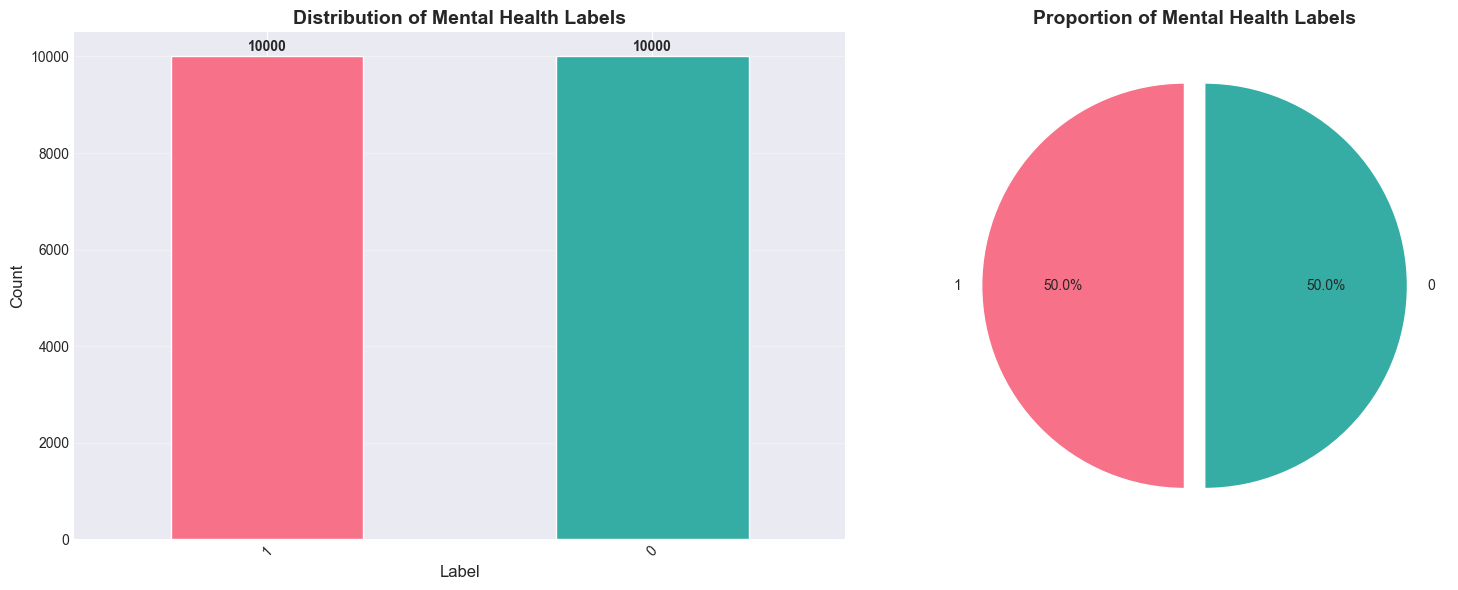

In [11]:
# Visualize label distribution
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Bar plot
label_counts.plot(kind='bar', ax=axes[0], color=sns.color_palette('husl', len(label_counts)))
axes[0].set_title('Distribution of Mental Health Labels', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Label', fontsize=12)
axes[0].set_ylabel('Count', fontsize=12)
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(axis='y', alpha=0.3)

# Add value labels on bars
for i, v in enumerate(label_counts):
    axes[0].text(i, v + 50, str(v), ha='center', va='bottom', fontweight='bold')

# Pie chart
colors = sns.color_palette('husl', len(label_counts))
axes[1].pie(label_counts, labels=label_counts.index, autopct='%1.1f%%', 
            startangle=90, colors=colors, explode=[0.05]*len(label_counts))
axes[1].set_title('Proportion of Mental Health Labels', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.savefig('../data/processed/label_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

## 5. Text Length Analysis

In [12]:
# Identify text column
text_col = [col for col in df.columns if 'text' in col.lower() or 'content' in col.lower() or 'message' in col.lower()]
if text_col:
    text_col = text_col[0]
else:
    print("Please specify the text column name:")
    print(df.columns.tolist())
    text_col = 'post_text'  # Default assumption

print(f"Using text column: {text_col}")

Using text column: post_text


In [13]:
# Calculate text statistics
df['char_count'] = df[text_col].astype(str).apply(len)
df['word_count'] = df[text_col].astype(str).apply(lambda x: len(x.split()))
df['sentence_count'] = df[text_col].astype(str).apply(lambda x: len(re.split(r'[.!?]+', x)))
df['avg_word_length'] = df[text_col].astype(str).apply(lambda x: np.mean([len(word) for word in x.split()] or [0]))

# Display statistics
text_stats = df[['char_count', 'word_count', 'sentence_count', 'avg_word_length']].describe()
print("\nText Statistics:")
print(text_stats)


Text Statistics:
         char_count    word_count  sentence_count  avg_word_length
count  20000.000000  20000.000000    20000.000000     20000.000000
mean      82.462950     12.521550        2.383750         6.512031
std       38.281974      6.858767        1.136992         3.186326
min        4.000000      1.000000        1.000000         1.625000
25%       50.000000      7.000000        2.000000         4.652174
50%       77.000000     12.000000        2.000000         5.666667
75%      118.000000     18.000000        3.000000         7.176471
max      169.000000     34.000000       13.000000        30.500000


In [14]:
# Text length by label
text_length_by_label = df.groupby(label_col)[['char_count', 'word_count']].agg(['mean', 'median', 'std'])
print("\nText Length Statistics by Label:")
print(text_length_by_label)


Text Length Statistics by Label:
      char_count                   word_count                 
            mean median        std       mean median       std
label                                                         
0        81.9331   74.0  39.717897    12.2244   11.0  7.166644
1        82.9928   80.0  36.784408    12.8187   12.0  6.523242


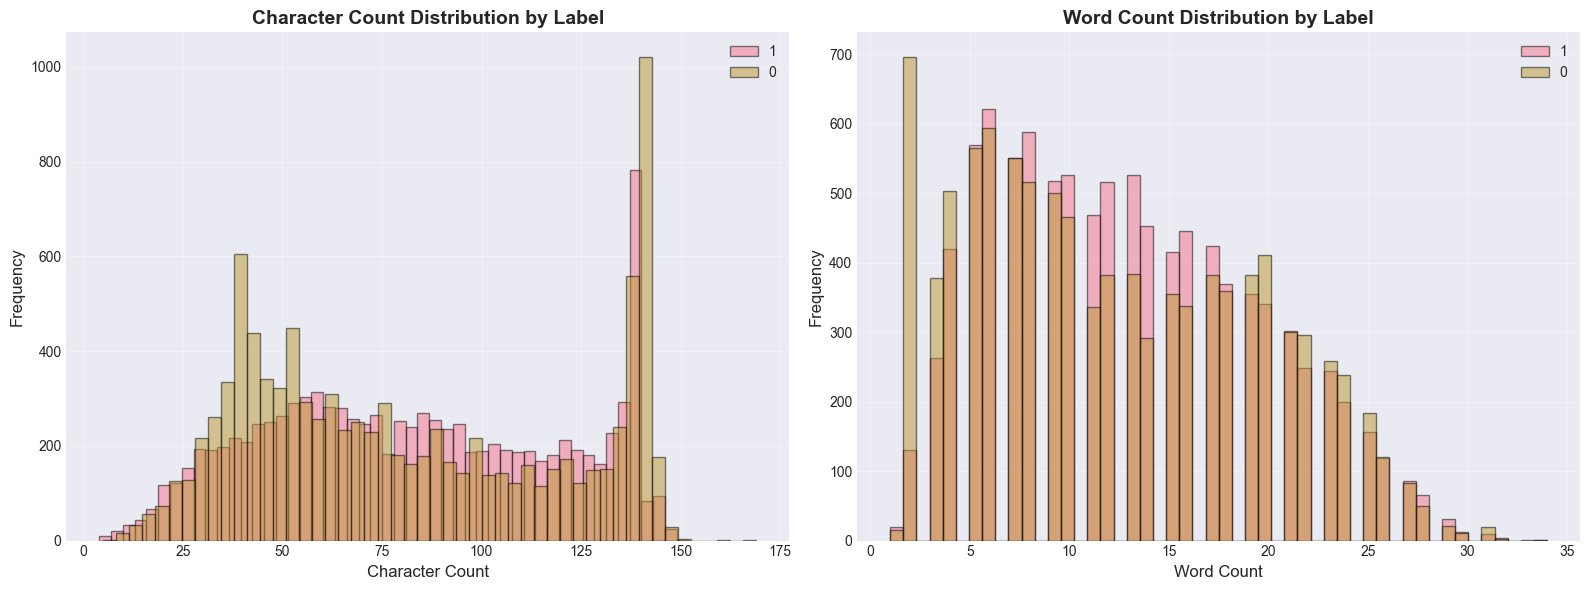

In [15]:
# Visualize text length distributions
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Character count distribution
for label in df[label_col].unique():
    subset = df[df[label_col] == label]['char_count']
    axes[0].hist(subset, bins=50, alpha=0.5, label=label, edgecolor='black')
axes[0].set_title('Character Count Distribution by Label', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Character Count', fontsize=12)
axes[0].set_ylabel('Frequency', fontsize=12)
axes[0].legend()
axes[0].grid(alpha=0.3)

# Word count distribution
for label in df[label_col].unique():
    subset = df[df[label_col] == label]['word_count']
    axes[1].hist(subset, bins=50, alpha=0.5, label=label, edgecolor='black')
axes[1].set_title('Word Count Distribution by Label', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Word Count', fontsize=12)
axes[1].set_ylabel('Frequency', fontsize=12)
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('../data/processed/text_length_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

## 6. Text Preprocessing Function

In [16]:
def clean_text(text):
    """
    Clean and preprocess text data
    """
    if pd.isna(text):
        return ""
    
    text = str(text)
    
    # Convert to lowercase
    text = text.lower()
    
    # Remove URLs
    text = re.sub(r"http\S+|www\S+|https\S+", "", text, flags=re.MULTILINE)
    
    # Remove user mentions and hashtags
    text = re.sub(r"@\w+|#\w+", "", text)
    
    # Remove punctuation
    text = text.translate(str.maketrans("", "", string.punctuation))
    
    # Remove extra whitespace
    text = " ".join(text.split())
    
    return text

# Apply cleaning
df["cleaned_text"] = df[text_col].apply(clean_text)

# Display examples
print("Example of text cleaning:")
print("-" * 100)
for i in range(min(3, len(df))):
    original = str(df[text_col].iloc[i])
    cleaned = str(df["cleaned_text"].iloc[i])
    print(f"Original: {original[:200]}{'...' if len(original) > 200 else ''}")
    print(f"Cleaned:  {cleaned[:200]}{'...' if len(cleaned) > 200 else ''}")
    print("-" * 100)

Example of text cleaning:
----------------------------------------------------------------------------------------------------
Original: It's just over 2 years since I was diagnosed with #anxiety and #depression. Today I'm taking a moment to reflect on how far I've come since.
Cleaned:  its just over 2 years since i was diagnosed with and today im taking a moment to reflect on how far ive come since
----------------------------------------------------------------------------------------------------
Original: It's Sunday, I need a break, so I'm planning to spend as little time as possible on the #A14...
Cleaned:  its sunday i need a break so im planning to spend as little time as possible on the
----------------------------------------------------------------------------------------------------
Original: Awake but tired. I need to sleep but my brain has other ideas...
Cleaned:  awake but tired i need to sleep but my brain has other ideas
-------------------------------------------------

## 7. Most Common Words Analysis

In [17]:
# Get stopwords
stop_words = set(stopwords.words('english'))

def get_top_words(texts, n=20, remove_stopwords=True):
    """
    Get top N most common words from texts
    """
    all_words = []
    for text in texts:
        words = text.split()
        if remove_stopwords:
            words = [word for word in words if word not in stop_words and len(word) > 2]
        all_words.extend(words)
    
    word_counts = Counter(all_words)
    return word_counts.most_common(n)

# Overall top words
top_words_overall = get_top_words(df['cleaned_text'])
print("\nTop 20 Most Common Words (Overall):")
print("-" * 50)
for word, count in top_words_overall:
    print(f"{word:20s}: {count:6d}")


Top 20 Most Common Words (Overall):
--------------------------------------------------
like                :    980
depression          :    827
dont                :    809
one                 :    690
get                 :    605
love                :    590
know                :    576
people              :    556
amp                 :    489
good                :    455
say                 :    412
new                 :    405
thank               :    399
time                :    395
need                :    372
youre               :    368
think               :    363
cant                :    360
want                :    358
see                 :    358


In [18]:
# Top words by label
print("\nTop 15 Words by Label:")
print("=" * 100)
for label in df[label_col].unique():
    subset_texts = df[df[label_col] == label]['cleaned_text']
    top_words = get_top_words(subset_texts, n=15)
    print(f"\nLABEL {label}:")
    print("-" * 50)
    for word, count in top_words:
        print(f"  {word:20s}: {count:6d}")


Top 15 Words by Label:

LABEL 1:
--------------------------------------------------
  depression          :    820
  like                :    516
  dont                :    426
  get                 :    393
  one                 :    328
  love                :    311
  people              :    301
  know                :    283
  treatments          :    268
  good                :    246
  amp                 :    233
  time                :    228
  new                 :    224
  overcome            :    219
  day                 :    214

LABEL 0:
--------------------------------------------------
  like                :    464
  dont                :    383
  one                 :    362
  thank               :    324
  trump               :    323
  say                 :    308
  know                :    293
  love                :    279
  yong                :    269
  twitter             :    266
  amp                 :    256
  people              :    255
  youre          

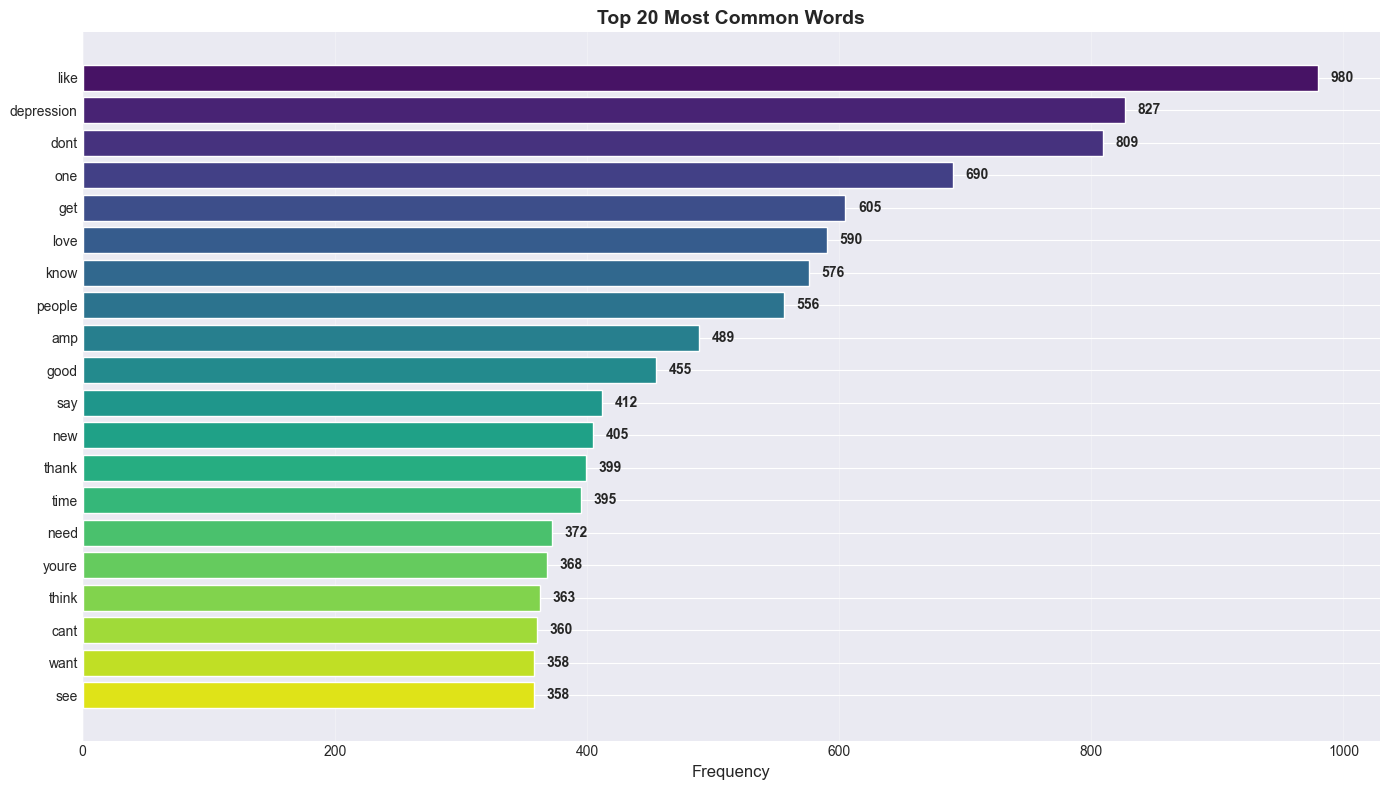

In [19]:
# Visualize top words
fig, axes = plt.subplots(1, 1, figsize=(14, 8))

words, counts = zip(*top_words_overall[:20])
y_pos = np.arange(len(words))

axes.barh(y_pos, counts, color=sns.color_palette('viridis', len(words)))
axes.set_yticks(y_pos)
axes.set_yticklabels(words)
axes.invert_yaxis()
axes.set_xlabel('Frequency', fontsize=12)
axes.set_title('Top 20 Most Common Words', fontsize=14, fontweight='bold')
axes.grid(axis='x', alpha=0.3)

# Add value labels
for i, v in enumerate(counts):
    axes.text(v + 10, i, str(v), va='center', fontweight='bold')

plt.tight_layout()
plt.savefig('../data/processed/top_words.png', dpi=300, bbox_inches='tight')
plt.show()

## 8. N-grams Analysis

In [20]:
from collections import defaultdict

def get_ngrams(texts, n=2, top_k=15):
    """
    Extract top N-grams from texts
    """
    ngrams = defaultdict(int)
    
    for text in texts:
        words = text.split()
        words = [w for w in words if w not in stop_words and len(w) > 2]
        
        for i in range(len(words) - n + 1):
            ngram = ' '.join(words[i:i+n])
            ngrams[ngram] += 1
    
    return sorted(ngrams.items(), key=lambda x: x[1], reverse=True)[:top_k]

# Bigrams (2-grams)
print("\nTop 15 Bigrams:")
print("-" * 50)
bigrams = get_ngrams(df['cleaned_text'], n=2)
for ngram, count in bigrams:
    print(f"{ngram:30s}: {count:6d}")

# Trigrams (3-grams)
print("\nTop 15 Trigrams:")
print("-" * 50)
trigrams = get_ngrams(df['cleaned_text'], n=3)
for ngram, count in trigrams:
    print(f"{ngram:40s}: {count:6d}")


Top 15 Bigrams:
--------------------------------------------------
depression treatments         :    257
following twitter             :    204
twitter thank                 :    204
overcome depression           :    198
say hello                     :    171
wearepayting foryong          :    104
thanks follow                 :    102
hello anytime                 :    100
yong paytforluckysun          :     75
dont know                     :     74
feel like                     :     68
zayn best                     :     57
best video                    :     57
happy birthday                :     56
mental health                 :     56

Top 15 Trigrams:
--------------------------------------------------
following twitter thank                 :    204
say hello anytime                       :    100
zayn best video                         :     57
hello anytime real                      :     32
happy new year                          :     26
say hello anytime…               

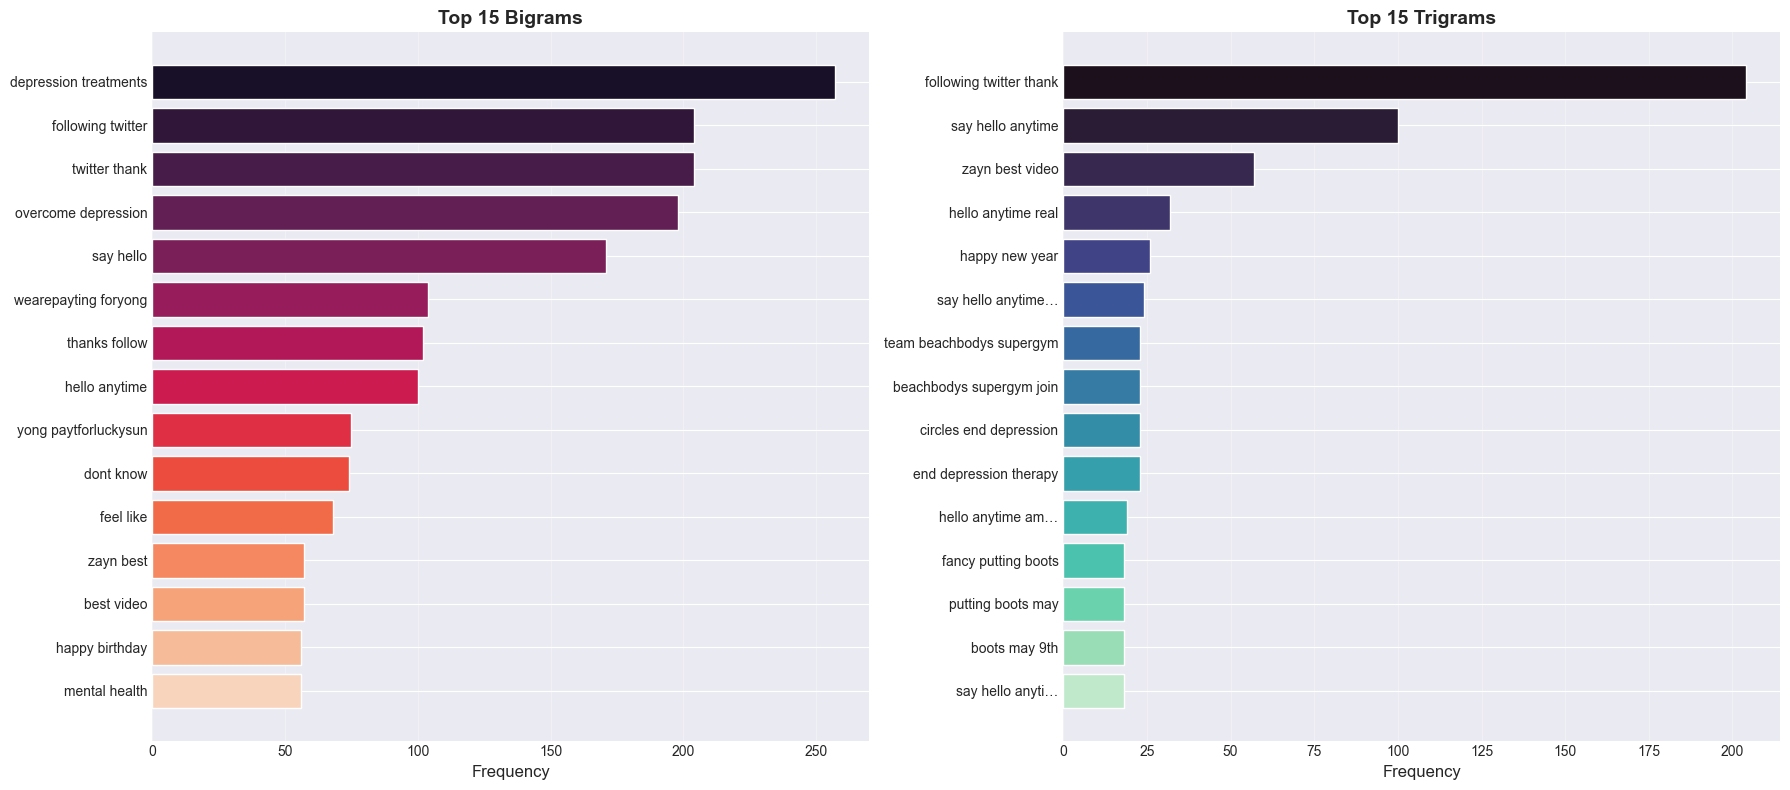

In [21]:
# Visualize bigrams and trigrams
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# Bigrams
bigram_words, bigram_counts = zip(*bigrams)
y_pos = np.arange(len(bigram_words))
axes[0].barh(y_pos, bigram_counts, color=sns.color_palette('rocket', len(bigram_words)))
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(bigram_words, fontsize=10)
axes[0].invert_yaxis()
axes[0].set_xlabel('Frequency', fontsize=12)
axes[0].set_title('Top 15 Bigrams', fontsize=14, fontweight='bold')
axes[0].grid(axis='x', alpha=0.3)

# Trigrams
trigram_words, trigram_counts = zip(*trigrams)
y_pos = np.arange(len(trigram_words))
axes[1].barh(y_pos, trigram_counts, color=sns.color_palette('mako', len(trigram_words)))
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(trigram_words, fontsize=10)
axes[1].invert_yaxis()
axes[1].set_xlabel('Frequency', fontsize=12)
axes[1].set_title('Top 15 Trigrams', fontsize=14, fontweight='bold')
axes[1].grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig('../data/processed/ngrams_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

## 9. Sentiment and Emotion Indicators

In [22]:
# Define emotion-related keywords
emotion_keywords = {
    'sadness': ['sad', 'depressed', 'depression', 'unhappy', 'miserable', 'sorrow', 'grief', 'hopeless'],
    'anxiety': ['anxious', 'anxiety', 'worried', 'nervous', 'panic', 'fear', 'stress', 'stressed'],
    'anger': ['angry', 'rage', 'furious', 'mad', 'irritated', 'frustrated', 'annoyed'],
    'loneliness': ['lonely', 'alone', 'isolated', 'solitary', 'abandoned'],
    'hope': ['hope', 'hopeful', 'optimistic', 'better', 'improve', 'recovery'],
    'suicidal': ['suicide', 'suicidal', 'kill myself', 'end it', 'die', 'death wish']
}

# Count emotion keywords
for emotion, keywords in emotion_keywords.items():
    df[f'{emotion}_count'] = df['cleaned_text'].apply(
        lambda x: sum([x.count(keyword) for keyword in keywords])
    )

# Calculate emotion prevalence
emotion_cols = [f'{emotion}_count' for emotion in emotion_keywords.keys()]
emotion_prevalence = df[emotion_cols].sum().sort_values(ascending=False)

print("\nEmotion Keyword Prevalence:")
print("-" * 50)
for emotion, count in emotion_prevalence.items():
    print(f"{emotion.replace('_count', ''):20s}: {count:6d}")


Emotion Keyword Prevalence:
--------------------------------------------------
sadness             :   1064
hope                :    442
anger               :    384
suicidal            :    333
anxiety             :    205
loneliness          :     55


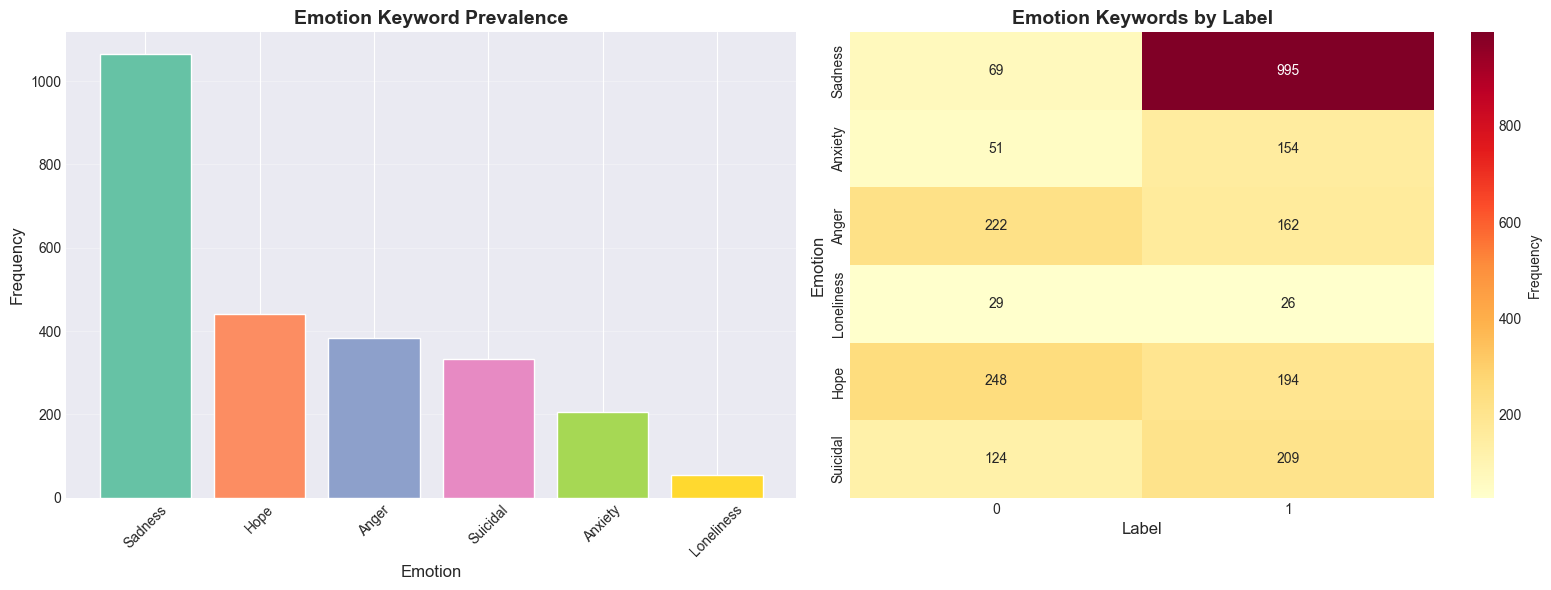

In [23]:
# Visualize emotion previalence
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Overall emotion distribution
emotion_names = [e.replace('_count', '').title() for e in emotion_prevalence.index]
axes[0].bar(emotion_names, emotion_prevalence.values, 
            color=sns.color_palette('Set2', len(emotion_names)))
axes[0].set_title('Emotion Keyword Prevalence', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Emotion', fontsize=12)
axes[0].set_ylabel('Frequency', fontsize=12)
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(axis='y', alpha=0.3)

# Emotion by label (heatmap)
emotion_by_label = df.groupby(label_col)[emotion_cols].sum()
emotion_by_label.columns = [c.replace('_count', '').title() for c in emotion_by_label.columns]
sns.heatmap(emotion_by_label.T, annot=True, fmt='d', cmap='YlOrRd', ax=axes[1], cbar_kws={'label': 'Frequency'})
axes[1].set_title('Emotion Keywords by Label', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Label', fontsize=12)
axes[1].set_ylabel('Emotion', fontsize=12)

plt.tight_layout()
plt.savefig('../data/processed/emotion_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

## 10. Special Characters and Patterns

In [24]:
# Analyze special patterns
df['has_url'] = df[text_col].astype(str).str.contains(r'http|www', case=False, regex=True)
df['has_mention'] = df[text_col].astype(str).str.contains(r'@\w+', regex=True)
df['has_hashtag'] = df[text_col].astype(str).str.contains(r'#\w+', regex=True)
df['has_emoji'] = df[text_col].astype(str).str.contains(r'[😀-🙏🌀-🗿🚀-🛿]', regex=True)
df['exclamation_count'] = df[text_col].astype(str).str.count('!')
df['question_count'] = df[text_col].astype(str).str.count('\?')

# Summary
pattern_stats = pd.DataFrame({
    'Pattern': ['URLs', 'Mentions', 'Hashtags', 'Emojis'],
    'Count': [
        df['has_url'].sum(),
        df['has_mention'].sum(),
        df['has_hashtag'].sum(),
        df['has_emoji'].sum()
    ],
    'Percentage': [
        (df['has_url'].sum() / len(df) * 100),
        (df['has_mention'].sum() / len(df) * 100),
        (df['has_hashtag'].sum() / len(df) * 100),
        (df['has_emoji'].sum() / len(df) * 100)
    ]
})

print("\nSpecial Pattern Statistics:")
print(pattern_stats.to_string(index=False))


Special Pattern Statistics:
 Pattern  Count  Percentage
    URLs   8576       42.88
Mentions   9806       49.03
Hashtags   2424       12.12
  Emojis   1324        6.62


## 11. Statistical Tests for Class Differences

In [25]:
# Perform statistical tests to check if text features differ significantly across labels
from scipy.stats import f_oneway, chi2_contingency

print("\nStatistical Tests for Label Differences:")
print("="*70)

# ANOVA for numerical features
numerical_features = ['word_count', 'char_count', 'avg_word_length']

for feature in numerical_features:
    groups = [df[df[label_col] == label][feature].values for label in df[label_col].unique()]
    statistic, p_value = f_oneway(*groups)
    print(f"\n{feature}:")
    print(f"  F-statistic: {statistic:.4f}")
    print(f"  P-value: {p_value:.4e}")
    print(f"  Significant: {'Yes' if p_value < 0.05 else 'No'}")


Statistical Tests for Label Differences:

word_count:
  F-statistic: 37.6083
  P-value: 8.8099e-10
  Significant: Yes

char_count:
  F-statistic: 3.8319
  P-value: 5.0301e-02
  Significant: No

avg_word_length:
  F-statistic: 517.3070
  P-value: 4.4289e-113
  Significant: Yes


## 12. Data Quality Checks

In [26]:
# Check for very short or empty texts
short_texts = df[df['word_count'] < 3]
print(f"\nTexts with fewer than 3 words: {len(short_texts)} ({len(short_texts)/len(df)*100:.2f}%)")

# Check for very long texts (potential outliers)
long_texts = df[df['word_count'] > df['word_count'].quantile(0.99)]
print(f"Texts longer than 99th percentile: {len(long_texts)} ({len(long_texts)/len(df)*100:.2f}%)")

# Display examples of short texts
if len(short_texts) > 0:
    print("\nExamples of very short texts:")
    print(short_texts[[text_col, label_col, 'word_count']].head())


Texts with fewer than 3 words: 863 (4.32%)
Texts longer than 99th percentile: 112 (0.56%)

Examples of very short texts:
                              post_text  label  word_count
138         This http://t.co/9ckfTcg4to      1           2
916   @aleahgarner_ daltonlikespancakes      1           2
967            @Chloe_Roknich whatever.      1           2
975              @Chloe_Roknich lies!c:      1           2
2760            @airieanna_lane what?!?      1           2


## 13. Summary Statistics and Key Findings

In [27]:
print("\n" + "="*80)
print("EDA SUMMARY AND KEY FINDINGS")
print("="*80)

print(f"\n1. DATASET OVERVIEW")
print(f"   - Total samples: {len(df):,}")
print(f"   - Number of classes: {df[label_col].nunique()}")
print(f"   - Classes: {', '.join(map(str, df[label_col].unique()))}")

print(f"\n2. CLASS DISTRIBUTION")
for label, count in label_counts.items():
    print(f"   - {str(label)}: {count:,} ({label_percentages[label]:.1f}%)")

print(f"\n3. TEXT STATISTICS")
print(f"   - Average word count: {df['word_count'].mean():.1f} ± {df['word_count'].std():.1f}")
print(f"   - Average character count: {df['char_count'].mean():.1f} ± {df['char_count'].std():.1f}")
print(f"   - Average word length: {df['avg_word_length'].mean():.2f} ± {df['avg_word_length'].std():.2f}")

print(f"\n4. DATA QUALITY")
print(f"   - Missing values: {df.isnull().sum().sum()}")
print(f"   - Duplicate rows: {duplicate_count}")
print(f"   - Very short texts (<3 words): {len(short_texts)}")

print(f"\n5. SPECIAL PATTERNS")
for idx, row in pattern_stats.iterrows():
    print(f"   - {row['Pattern']}: {row['Count']:,} ({row['Percentage']:.1f}%)")

print(f"\n6. TOP EMOTION INDICATORS")
top_3_emotions = emotion_prevalence.head(3)
for emotion, count in top_3_emotions.items():
    print(f"   - {emotion.replace('_count', '').title()}: {count:,} occurrences")

print("\n" + "="*80)


EDA SUMMARY AND KEY FINDINGS

1. DATASET OVERVIEW
   - Total samples: 20,000
   - Number of classes: 2
   - Classes: 1, 0

2. CLASS DISTRIBUTION
   - 1: 10,000 (50.0%)
   - 0: 10,000 (50.0%)

3. TEXT STATISTICS
   - Average word count: 12.5 ± 6.9
   - Average character count: 82.5 ± 38.3
   - Average word length: 6.51 ± 3.19

4. DATA QUALITY
   - Missing values: 0
   - Duplicate rows: 0
   - Very short texts (<3 words): 863

5. SPECIAL PATTERNS
   - URLs: 8,576 (42.9%)
   - Mentions: 9,806 (49.0%)
   - Hashtags: 2,424 (12.1%)
   - Emojis: 1,324 (6.6%)

6. TOP EMOTION INDICATORS
   - Sadness: 1,064 occurrences
   - Hope: 442 occurrences
   - Anger: 384 occurrences



## 15. Save Processed Data and Summary

In [28]:
# Create processed directory if it doesn't exist
import os
os.makedirs('../data/processed', exist_ok=True)

# Save cleaned dataset
output_path = '../data/processed/mental_health_cleaned.csv'
df.to_csv(output_path, index=False)
print(f"
Cleaned dataset saved to: {output_path}")
print(f"  - Rows: {len(df):,}")
print(f"  - Columns: {len(df.columns)}")

# Save summary statistics
summary_stats = {
    'total_samples': int(len(df)),
    'n_classes': int(df[label_col].nunique()),
    'label_distribution': {str(k): int(v) for k, v in label_counts.items()},
    'avg_word_count': float(df['word_count'].mean()),
    'avg_char_count': float(df['char_count'].mean()),
    'missing_values': int(df.isnull().sum().sum()),
    'duplicates': int(duplicate_count)
}

import json
with open('../data/processed/eda_summary.json', 'w') as f:
    json.dump(summary_stats, f, indent=4)
print(f"
Summary statistics saved to: ../data/processed/eda_summary.json")
print(f"
Processed data ready for model training!")

Cleaned dataset saved to: ../data/processed/mental_health_cleaned.csv
Summary statistics saved to: ../data/processed/eda_summary.json
